<a href="https://colab.research.google.com/github/anupbagale/python-for-ai-ml/blob/main/16-time-series-and-recommendations/01_lesson.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Module 16: Time Series and Recommendations

This module covers two kinds of problem that look different but share one hard rule: **the test set is the future**.

**Time series forecasting** predicts what a quantity will be tomorrow, next week or next month, from its past: sales, electricity demand, website traffic, bikes rented. The observations come in order, each one depends on the ones before, and the patterns repeat over days, weeks and years. Ordinary cross-validation, which shuffles the rows, gives dishonest answers here.

**Recommender systems** predict what a person will want next: the next film to watch, product to buy or song to play. They learn from a huge, mostly empty table of who liked or bought what. They power much of the modern internet, and they also have to be evaluated on what people did **later**, not on a shuffled sample of what they already did.

Part 1 is about time series, Part 2 about recommendations. The mini project applies both to real data.

**Contents**

Part 1: Time series

1. What makes time series different
2. Trend, seasonality and noise
3. Autocorrelation: the past predicts the future
4. Baselines you must beat
5. Exponential smoothing
6. Honest validation for time series
7. Forecasting as supervised learning
8. Many steps ahead
9. Trend and extrapolation
10. How sure is the forecast?

Part 2: Recommendations

11. The recommendation problem
12. Baselines: averages and biases
13. Collaborative filtering with similarities
14. Matrix factorisation
15. Evaluating recommenders

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn

DATA_URL = "https://raw.githubusercontent.com/anupbagale/python-for-ai-ml/main/16-time-series-and-recommendations/data/bike_day.csv"
local = Path("data/bike_day.csv")
bikes = pd.read_csv(local if local.exists() else DATA_URL, parse_dates=["dteday"])
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.1


In [2]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Categorical colours, always used in this order. The first three are checked to stay
# distinguishable for the common forms of colour blindness, even in scatter plots.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

SURFACE = "#fcfcfb"     # chart background
INK = "#0b0b0b"         # titles and important text
INK_2 = "#52514e"       # labels and tick text
MUTED = "#898781"       # de-emphasised marks
GRID = "#e1e0d9"        # gridlines
AXIS = "#c3c2b7"        # axis lines

# Sequential: one hue, light to dark, for magnitude (heatmaps, counts)
SEQUENTIAL = LinearSegmentedColormap.from_list(
    "course_blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
# Diverging: two opposite hues with a neutral grey in the middle, for values around zero
DIVERGING = LinearSegmentedColormap.from_list(
    "course_diverging", ["#184f95", "#86b6ef", "#f0efec", "#f0a3a2", "#c23a3a"])


def use_course_style():
    for cmap in (SEQUENTIAL, DIVERGING):
        if cmap.name not in mpl.colormaps:
            mpl.colormaps.register(cmap)
    mpl.rcParams.update({
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "figure.dpi": 100,
        "savefig.dpi": 150,
        "figure.figsize": (7, 4),
        "font.size": 10,
        "text.color": INK,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.titlepad": 10,
        "axes.labelcolor": INK_2,
        "axes.edgecolor": AXIS,
        "axes.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "grid.linestyle": "-",
        "xtick.color": AXIS,
        "ytick.color": AXIS,
        "xtick.labelcolor": INK_2,
        "ytick.labelcolor": INK_2,
        "axes.prop_cycle": mpl.cycler(color=PALETTE),
        "lines.linewidth": 1.6,
        "lines.solid_capstyle": "round",
        "lines.markersize": 6,
        "patch.linewidth": 0,
        "legend.frameon": False,
        "legend.labelcolor": INK_2,
        "image.cmap": "course_blues",
    })


use_course_style()

# Part 1: Time series

## 1. What makes time series different

The data for Part 1 is the number of bikes rented each day from Capital Bikeshare, the bike-sharing system of Washington, D.C., over 2011 and 2012, with the weather on each day. It was published by Hadi Fanaee-T and João Gama in 2013.

In [3]:
daily = bikes.set_index("dteday")["cnt"].asfreq("D")
daily.index.name = "date"
print(f"{len(daily)} days, from {daily.index.min():%d %b %Y} to {daily.index.max():%d %b %Y}")
print(f"missing days: {daily.isna().sum()}")
daily.head()

731 days, from 01 Jan 2011 to 31 Dec 2012
missing days: 0


date
2011-01-01     985
2011-01-02     801
2011-01-03    1349
2011-01-04    1562
2011-01-05    1600
Freq: D, Name: cnt, dtype: int64

`asfreq("D")` sets the index to a regular daily calendar, so a missing day would show up as a gap (`NaN`) instead of silently vanishing. Here every day is present. Always check this: many time series tools assume equal spacing, and a missing week quietly breaks lag features.

Three things set time series apart from the tables of earlier modules:

- **Order matters.** Shuffling the rows destroys information. Yesterday is more informative about today than a day last year.
- **Observations depend on each other.** A busy day tends to be followed by another busy day. The rows aren't independent, which is what ordinary cross-validation assumes.
- **The question is about the future.** A forecast is used before the outcome is known, so only the past can be used to make it. That sounds obvious, and it's still the most common source of mistakes.

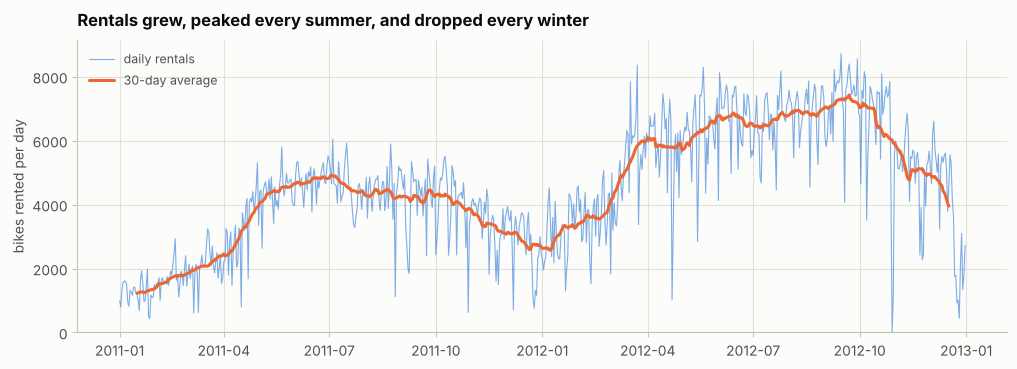

In [4]:
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(daily.index, daily, color=PALETTE[0], linewidth=0.8, alpha=0.6, label="daily rentals")
ax.plot(daily.index, daily.rolling(30, center=True).mean(), color=PALETTE[1], linewidth=2.2, label="30-day average")
ax.set_ylabel("bikes rented per day")
ax.set_ylim(0, None)
ax.legend(loc="upper left", fontsize=9)
ax.set_title("Rentals grew, peaked every summer, and dropped every winter")
plt.show()

Even in one picture, several patterns are visible: rentals grew from 2011 to 2012, they rise in summer and fall in winter, and individual days jump around a lot (rain, holidays, the occasional storm). The thick line is a **rolling mean**: each point is the average of the 30 days around it, which smooths out the day-to-day noise.

## 2. Trend, seasonality and noise

It's useful to think of a time series as a combination of three parts:

- **Trend**: the slow, long-term direction (growth of the bike system).
- **Seasonality**: patterns that repeat with a fixed period: every week, every year, every day for hourly data.
- **Noise** (the remainder): what's left over, from weather, events and chance.

A simple way to separate them, by hand: estimate the trend with a long rolling mean, remove it, and average what's left for each position in the cycle. For the weekly pattern, that means averaging by day of the week:

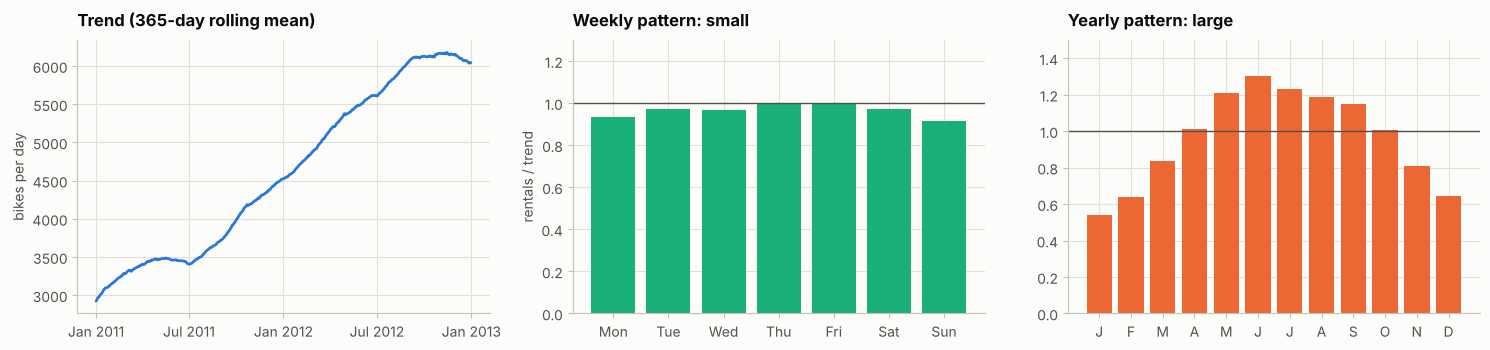

weekday effect: {0: 0.94, 1: 0.97, 2: 0.97, 3: 0.99, 4: 1.0, 5: 0.97, 6: 0.92}


In [5]:
trend = daily.rolling(365, center=True, min_periods=180).mean()
detrended = daily / trend                                    # rentals relative to the trend at the time
weekday_effect = detrended.groupby(daily.index.dayofweek).mean()
month_effect = detrended.groupby(daily.index.month).mean()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
axes[0].plot(daily.index, trend, color=PALETTE[0], linewidth=2)
axes[0].xaxis.set_major_locator(mpl.dates.MonthLocator(bymonth=[1, 7]))
axes[0].xaxis.set_major_formatter(mpl.dates.DateFormatter("%b %Y"))
axes[0].set_title("Trend (365-day rolling mean)")
axes[0].set_ylabel("bikes per day")
axes[1].bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], weekday_effect, color=PALETTE[2])
axes[1].axhline(1, color=INK_2, linewidth=1)
axes[1].set_ylim(0, 1.3)
axes[1].set_title("Weekly pattern: small")
axes[1].set_ylabel("rentals / trend")
axes[2].bar(range(1, 13), month_effect, color=PALETTE[1])
axes[2].set_xticks(range(1, 13), ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
axes[2].axhline(1, color=INK_2, linewidth=1)
axes[2].set_ylim(0, 1.5)
axes[2].set_title("Yearly pattern: large")
fig.tight_layout()
plt.show()
print("weekday effect:", weekday_effect.round(2).to_dict())

We divided by the trend rather than subtracting it, because the seasonal swings grow as the system grows: a busy summer day in 2012 is more bikes above average than in 2011. A pattern that scales with the level like this is called **multiplicative**; one that adds a fixed amount is **additive**.

The **yearly** pattern is large: summer months run about 30% above the trend and January about half below. The **weekly** pattern is surprisingly small for daily totals, because two groups of riders cancel out: registered commuters ride on weekdays and casual riders at weekends. (The hourly data in the mini project shows a much stronger daily pattern.)

Libraries do this more carefully: `statsmodels.tsa.seasonal.STL` is a widely used method that handles several seasonal periods and changing seasonal shapes. The idea is the same.

## 3. Autocorrelation: the past predicts the future

**Autocorrelation** is the correlation between a series and a lagged copy of itself: how similar is today's value to the value `k` days ago? It's the reason forecasting works at all.

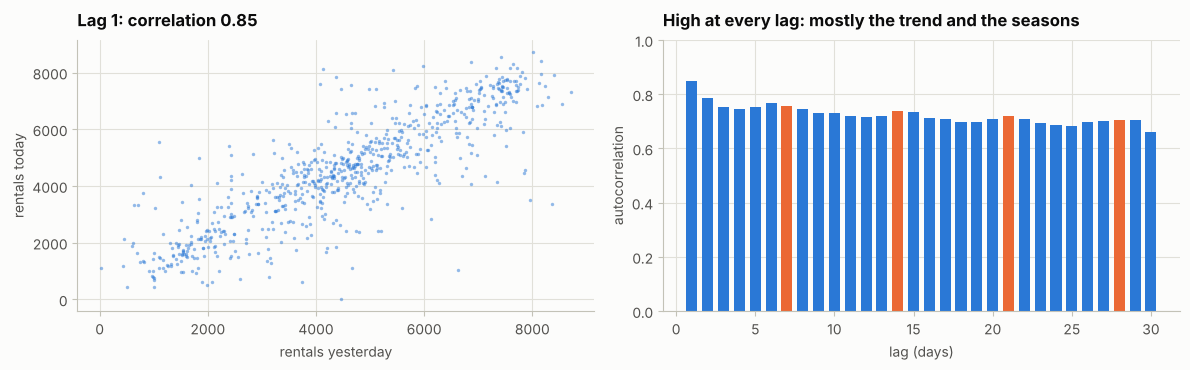

In [6]:
lags = range(1, 31)
autocorr = [daily.autocorr(lag=k) for k in lags]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].scatter(daily.shift(1), daily, s=6, color=PALETTE[0], alpha=0.5)
axes[0].set_xlabel("rentals yesterday")
axes[0].set_ylabel("rentals today")
axes[0].set_title(f"Lag 1: correlation {daily.autocorr(1):.2f}")
axes[1].bar(list(lags), autocorr, color=PALETTE[0], width=0.7)
for k in [7, 14, 21, 28]:
    axes[1].bar(k, autocorr[k - 1], color=PALETTE[1], width=0.7)
axes[1].set_xlabel("lag (days)")
axes[1].set_ylabel("autocorrelation")
axes[1].set_ylim(0, 1)
axes[1].set_title("High at every lag: mostly the trend and the seasons")
fig.tight_layout()
plt.show()

Today is strongly correlated with yesterday, and still strongly correlated with a month ago. That's mostly the slow trend and the seasons: any two days in summer 2012 are both "busy". The weekly lags (in orange) are only slightly higher than their neighbours, which matches the small weekly pattern.

Autocorrelation is useful and dangerous. Useful, because recent values are good predictors. Dangerous, because a model can look excellent simply by copying yesterday, and because it makes the rows dependent, which breaks random cross-validation (section 6).

## 4. Baselines you must beat

Before any model, compute the simple forecasts. They're often surprisingly hard to beat, and any model that can't beat them is useless however sophisticated it is.

- **Naive**: tomorrow will be like today.
- **Seasonal naive**: the same day of the season last time (here, the same weekday last week).
- **Moving average**: the average of the last few days.

We'll forecast each day of the last quarter of 2012 using only data before it, and measure the errors:

In [7]:
test_start = "2012-10-01"
test = daily[test_start:]

baselines = {
    "naive (yesterday)": daily.shift(1)[test_start:],
    "seasonal naive (a week ago)": daily.shift(7)[test_start:],
    "moving average (last 7 days)": daily.shift(1).rolling(7).mean()[test_start:],
    "moving average (last 28 days)": daily.shift(1).rolling(28).mean()[test_start:],
}


def errors(actual, forecast):
    e = actual - forecast
    return {"MAE": np.mean(np.abs(e)), "RMSE": np.sqrt(np.mean(e ** 2)), "MAPE": np.mean(np.abs(e) / actual)}


pd.DataFrame({name: errors(test, f) for name, f in baselines.items()}).T.round(3)

,MAE,RMSE,MAPE
naive (yesterday),951.739,1380.166,2.438
seasonal naive (a week ago),1457.587,2047.168,4.030
moving average (last 7 days),1043.140,1517.930,3.840
moving average (last 28 days),1125.490,1682.742,3.875


Notice the `shift(1)` before `rolling`: the 7-day average used to forecast a day must stop at the day **before** it. Without the shift, the average would include the very value we're forecasting, a subtle leak (Exercise 6).

Some notes on the metrics:

- **MAE** (mean absolute error) is in bikes per day and easy to explain.
- **RMSE** punishes big misses more.
- **MAPE** (mean absolute percentage error) is popular with businesses because it's a percentage, but it explodes when actual values are near zero (look at the size of it here, driven by a handful of storm days), and it punishes over-forecasts and under-forecasts differently. Use it with care.

A fourth measure, **MASE** (mean absolute scaled error, Rob Hyndman and Anne Koehler, 2006), divides a model's MAE by the MAE of the naive forecast on the training data. Below 1 means the model beats naive. It's a fair way to compare forecasts across series of different sizes.

On this quarter, yesterday's value is the best of the four baselines. That sets the bar.

## 5. Exponential smoothing

A moving average gives the last few days equal weight and ignores everything before. **Exponential smoothing** gives every past value some weight, with weights that fade the further back you go. Its forecast is updated with each new observation:

$$\text{level}_t = \alpha \, y_t + (1 - \alpha) \, \text{level}_{t-1}$$

and the forecast for tomorrow is today's level. `α` between 0 and 1 controls how quickly old values are forgotten: close to 1 reacts fast (almost the naive forecast); close to 0 is smooth and slow.

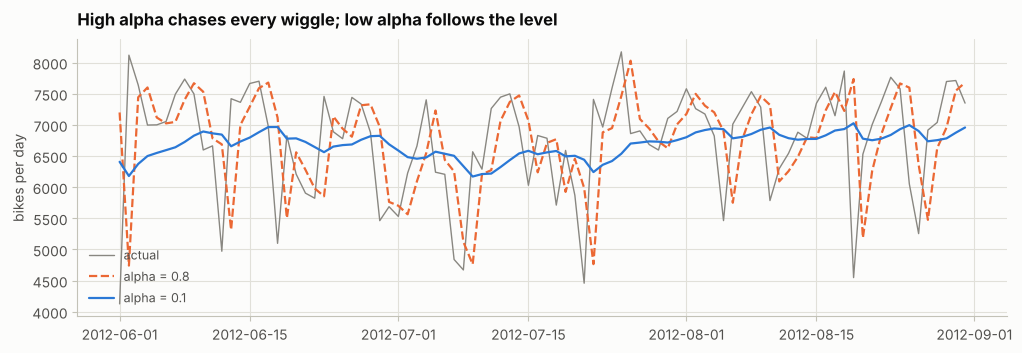

alpha 0.1: test MAE 1018
alpha 0.3: test MAE 970
alpha 0.5: test MAE 943
alpha 0.8: test MAE 927
naive:     test MAE 952


In [8]:
def exponential_smoothing(series, alpha):
    """One-step-ahead forecasts: forecast[t] uses values up to t - 1."""
    values = series.to_numpy(dtype=float)
    forecasts = np.empty(len(values))
    level = values[0]
    forecasts[0] = np.nan
    for t in range(1, len(values)):
        forecasts[t] = level
        level = alpha * values[t] + (1 - alpha) * level
    return pd.Series(forecasts, index=series.index)


fig, ax = plt.subplots(figsize=(12, 3.6))
window = daily["2012-06-01":"2012-08-31"]
ax.plot(window.index, window, color=MUTED, linewidth=1, label="actual")
for alpha, colour, style in [(0.8, PALETTE[1], "--"), (0.1, PALETTE[0], "-")]:
    ax.plot(window.index, exponential_smoothing(daily, alpha)[window.index], color=colour, linestyle=style, linewidth=1.6,
            label=f"alpha = {alpha}")
ax.set_ylabel("bikes per day")
ax.legend(loc="lower left", fontsize=9)
ax.set_title("High alpha chases every wiggle; low alpha follows the level")
plt.show()

for alpha in [0.1, 0.3, 0.5, 0.8]:
    print(f"alpha {alpha}: test MAE {errors(test, exponential_smoothing(daily, alpha)[test_start:])['MAE']:.0f}")
print(f"naive:     test MAE {errors(test, baselines['naive (yesterday)'])['MAE']:.0f}")

On this quarter a high `α` works best, reacting quickly like the naive forecast while smoothing a little of the noise, and it edges out the naive forecast. In practice `α` is chosen by minimising the error on past data.

Extensions add more components, each with its own smoothing constant: **Holt's method** adds a trend (Exercise 10), and the **Holt-Winters** method adds seasonality. Together with **ARIMA** models, which describe a series through its own lags and past errors, these are the classic statistical forecasting methods. The `statsmodels` library implements them (`ExponentialSmoothing`, `ARIMA`), and they remain strong choices for single, short series. Rob Hyndman and George Athanasopoulos's free online book *Forecasting: Principles and Practice* is the standard introduction.

## 6. Honest validation for time series

Random K-fold cross-validation (Module 11) shuffles the rows. For time series, that means training on days **after** the days being tested, and testing on days whose neighbours (almost identical, because of autocorrelation) are in the training set. The scores come out too good.

The honest alternative is to always train on the past and test on the future. **Expanding-window** validation does this repeatedly: train on everything up to a point, test on the next block, move the point forward, repeat. scikit-learn's `TimeSeriesSplit` produces these splits:

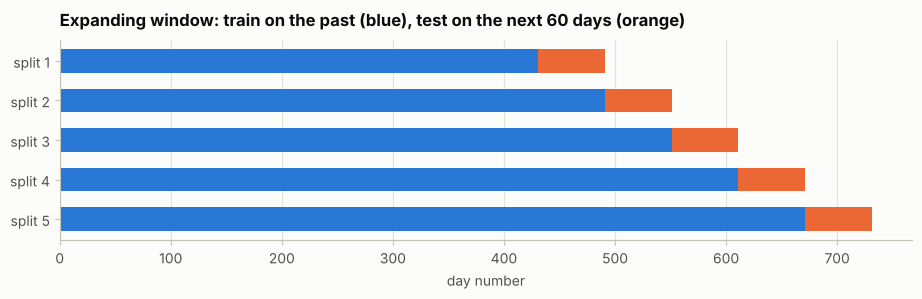

In [9]:
from sklearn.model_selection import KFold, TimeSeriesSplit, cross_val_score

tscv = TimeSeriesSplit(n_splits=5, test_size=60)
fig, ax = plt.subplots(figsize=(11, 2.6))
for fold, (train_idx, test_idx) in enumerate(tscv.split(daily)):
    ax.barh(fold, len(train_idx), left=0, color=PALETTE[0], height=0.6)
    ax.barh(fold, len(test_idx), left=test_idx[0], color=PALETTE[1], height=0.6)
ax.set_yticks(range(5), [f"split {i + 1}" for i in range(5)])
ax.set_xlabel("day number")
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_title("Expanding window: train on the past (blue), test on the next 60 days (orange)")
plt.show()

Here's how much difference it makes. A model that predicts today's rentals from the weather and the last two weeks of rentals, evaluated both ways:

In [10]:
from sklearn.ensemble import HistGradientBoostingRegressor

features = pd.DataFrame({f"lag_{k}": daily.shift(k) for k in range(1, 15)})
features["temp"] = bikes["temp"].to_numpy()
features["weekday"] = daily.index.dayofweek
features["workingday"] = bikes["workingday"].to_numpy()
features["weathersit"] = bikes["weathersit"].to_numpy()
supervised = features.assign(target=daily).dropna()
X_ts, y_ts = supervised.drop(columns="target"), supervised["target"]

model = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, random_state=0)
random_cv = -cross_val_score(model, X_ts, y_ts, cv=KFold(5, shuffle=True, random_state=0), scoring="neg_mean_absolute_error").mean()
time_cv = -cross_val_score(model, X_ts, y_ts, cv=TimeSeriesSplit(n_splits=5, test_size=60), scoring="neg_mean_absolute_error").mean()
print(f"random K-fold MAE:   {random_cv:.0f}")
print(f"time-ordered MAE:    {time_cv:.0f}")

random K-fold MAE:   609
time-ordered MAE:    943


The random folds report a much smaller error than the time-ordered ones. The random folds aren't "wrong" arithmetic; they answer a question nobody asked: how well can the model fill in random missing days in the middle of a period it has mostly seen? The time-ordered folds answer the real question: how well does it forecast days it hasn't reached yet, including periods with conditions it hasn't seen (here, the record levels of 2012)?

Two refinements:

- **A gap**: if features look back several days, leave a gap between the training and test periods (`TimeSeriesSplit(gap=...)`) so the end of training doesn't overlap with what the test period's features use.
- **A sliding window** (`max_train_size=...`): train on only the most recent stretch, when old data describes a world that no longer exists.

## 7. Forecasting as supervised learning

The model above shows the most practical modern approach: turn the series into an ordinary table, where each row is a time point, the target is the value to forecast, and the features are things known **before** it:

- **lag features**: the value 1 day ago, 7 days ago, and so on
- **rolling features**: the mean of the last 7 days, the maximum of the last 28, and so on, always ending before the target
- **calendar features**: day of the week, month, holidays
- **known future information**: things you'll know in advance, such as scheduled holidays, planned promotions, or a weather **forecast**

Then any regression model from Modules 12 and 14 can be used, and gradient boosting is usually the strongest. This is how many winning entries in forecasting competitions work: the M5 competition (2020), on Walmart sales, was won by gradient-boosted trees on lag and calendar features.

The rule for every feature is the same: **would I know this value at the moment I make the forecast?** Here's what a leak looks like. A "rolling mean of the last 7 days" computed without shifting first includes today, the value we're trying to predict:

In [11]:
leaky = features.copy()
leaky["mean_7"] = daily.rolling(7).mean()                    # includes today
honest = features.copy()
honest["mean_7"] = daily.shift(1).rolling(7).mean()          # ends yesterday

for name, table in [("honest rolling mean", honest), ("leaky rolling mean", leaky)]:
    data = table.assign(target=daily).dropna()
    mae = -cross_val_score(model, data.drop(columns="target"), data["target"], cv=TimeSeriesSplit(n_splits=5, test_size=60),
                           scoring="neg_mean_absolute_error").mean()
    print(f"{name:<20} time-ordered MAE {mae:.0f}")

honest rolling mean  time-ordered MAE 940


leaky rolling mean   time-ordered MAE 852


The leaky feature makes the error drop by about a tenth, even though the validation is time-ordered, because the leak is inside the features: one seventh of the "rolling mean" is the target itself, and with yesterday's lags also available, the model can recover it. In production, today's value isn't available when the forecast is made, so the real error would be the honest one. This kind of leak is easy to write and hard to spot, which is why the shift-before-roll habit matters.

## 8. Many steps ahead

Often you need more than tomorrow: the next 7 days, the next month. Two main strategies:

- **Recursive**: train one model to forecast one step ahead. To forecast two steps, feed the first forecast back in as if it were a real value, and repeat. Simple, but errors compound: a mistake on day 1 becomes an input for day 2.
- **Direct**: train a separate model for each horizon: one for "tomorrow", one for "in two days", and so on. Each model only uses information available at the forecast time. More models, but no compounding.

Whatever the strategy, **errors grow with the horizon**: the further ahead, the less the recent past tells you. Here's a direct forecast for horizons of 1 to 28 days, each model using only lags that would be available at that horizon:

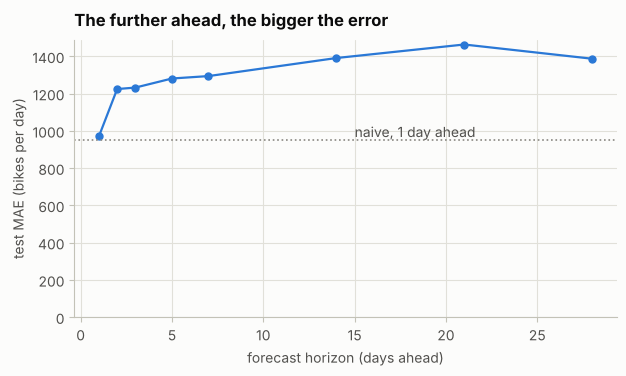

In [12]:
horizons = [1, 2, 3, 5, 7, 14, 21, 28]
horizon_mae = []
for h in horizons:
    direct = pd.DataFrame({f"lag_{k}": daily.shift(k) for k in range(h, h + 14)})     # nothing more recent than h days ago
    direct["weekday"] = daily.index.dayofweek
    direct["workingday"] = bikes["workingday"].to_numpy()
    data = direct.assign(target=daily).dropna()
    train, test_part = data[:"2012-09-30"], data[test_start:]
    fitted = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, random_state=0).fit(train.drop(columns="target"), train["target"])
    horizon_mae.append(np.mean(np.abs(test_part["target"] - fitted.predict(test_part.drop(columns="target")))))

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(horizons, horizon_mae, color=PALETTE[0], marker="o", markersize=5)
ax.axhline(errors(test, baselines["naive (yesterday)"])["MAE"], color=MUTED, linestyle=":", linewidth=1.2)
ax.text(15, errors(test, baselines["naive (yesterday)"])["MAE"] + 15, "naive, 1 day ahead", color=INK_2)
ax.set_xlabel("forecast horizon (days ahead)")
ax.set_ylabel("test MAE (bikes per day)")
ax.set_ylim(0, None)
ax.set_title("The further ahead, the bigger the error")
plt.show()

The error grows quickly over the first few days and then levels off: beyond a week or two, recent values carry little extra information, and the forecast falls back on the general level and the calendar. Even the one-day model only matches the naive forecast here. Without weather information, there's little a model can add to "about the same as yesterday", and it can't anticipate rainy days at any horizon, which is a large part of the remaining error.

## 9. Trend and extrapolation

Module 14 showed that trees can't predict outside the range of values they were trained on. That's a serious problem for a growing series. Train gradient boosting on 2011 alone, using only calendar and weather features, and ask it about 2012:

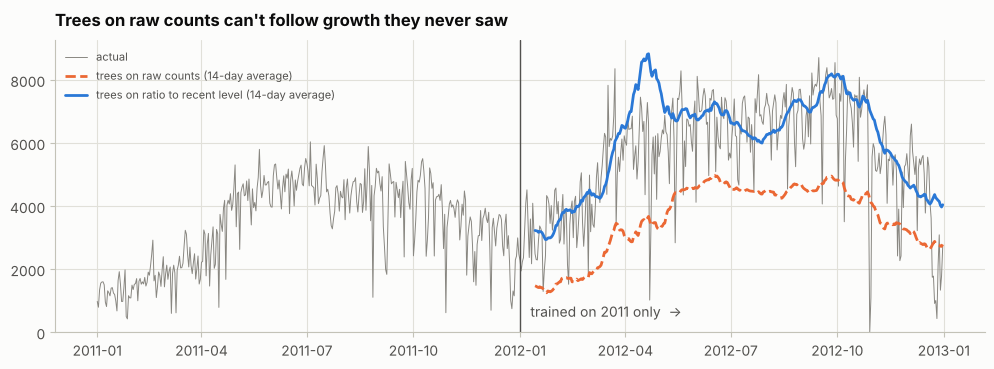

raw counts             2012 MAE 2140
ratio to recent level  2012 MAE 871


In [13]:
calendar = pd.DataFrame({"month": daily.index.month, "weekday": daily.index.dayofweek, "workingday": bikes["workingday"].to_numpy(),
                         "temp": bikes["temp"].to_numpy(), "hum": bikes["hum"].to_numpy(), "weathersit": bikes["weathersit"].to_numpy()},
                        index=daily.index)
train_2011, test_2012 = calendar[:"2011-12-31"], calendar["2012-01-01":]
tree_2011 = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, random_state=0).fit(train_2011, daily[:"2011-12-31"])

# The fix: model the ratio to the recent level, which stays in a familiar range as the system grows
level = daily.shift(1).rolling(28).mean()
ratio = daily / level
mask = ratio[:"2011-12-31"].notna()
ratio_2011 = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, random_state=0).fit(train_2011[mask], ratio[:"2011-12-31"][mask])

raw_forecast = pd.Series(tree_2011.predict(test_2012), index=test_2012.index)
ratio_forecast = pd.Series(ratio_2011.predict(test_2012), index=test_2012.index) * level["2012-01-01":]

fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(daily.index, daily, color=MUTED, linewidth=0.7, label="actual")
ax.plot(raw_forecast.index, raw_forecast.rolling(14).mean(), color=PALETTE[1], linewidth=2, linestyle="--", label="trees on raw counts (14-day average)")
ax.plot(ratio_forecast.index, ratio_forecast.rolling(14).mean(), color=PALETTE[0], linewidth=2, label="trees on ratio to recent level (14-day average)")
ax.axvline(pd.Timestamp("2012-01-01"), color=INK_2, linewidth=1)
ax.text(pd.Timestamp("2012-01-10"), 500, "trained on 2011 only  →", color=INK_2)
ax.set_ylim(0, None)
ax.legend(loc="upper left", fontsize=8)
ax.set_title("Trees on raw counts can't follow growth they never saw")
plt.show()
for name, f in [("raw counts", raw_forecast), ("ratio to recent level", ratio_forecast)]:
    print(f"{name:<22} 2012 MAE {errors(daily['2012-01-01':], f)['MAE']:.0f}")

Trained on 2011, the tree model on raw counts reproduces 2011's levels in 2012: it gets the seasonal shape right but stays far below the actual rentals, because it has never seen a day with more than 2011's busiest rentals. Modelling the **ratio** to the recent level instead keeps the target in a familiar range however much the system grows; multiplying back by the level then follows the growth, and the error drops a lot. Other common fixes: model the **change** from the previous period (differencing), divide out a fitted trend, or let a linear model handle the trend and trees the rest.

## 10. How sure is the forecast?

A single number is rarely enough for a decision. A bike operator needs to know not just "about 6,000 rentals" but "probably between 4,500 and 7,500", to plan bikes and staff. A **prediction interval** gives that range.

One direct method is **quantile regression**: train a model to predict a chosen quantile instead of the mean. With the pinball (quantile) loss, a model for the 0.1 quantile learns a value that the actual falls below about 10% of the time; one for 0.9, a value it falls below 90% of the time. Together they give an 80% interval. Gradient boosting supports this with `loss="quantile"`:

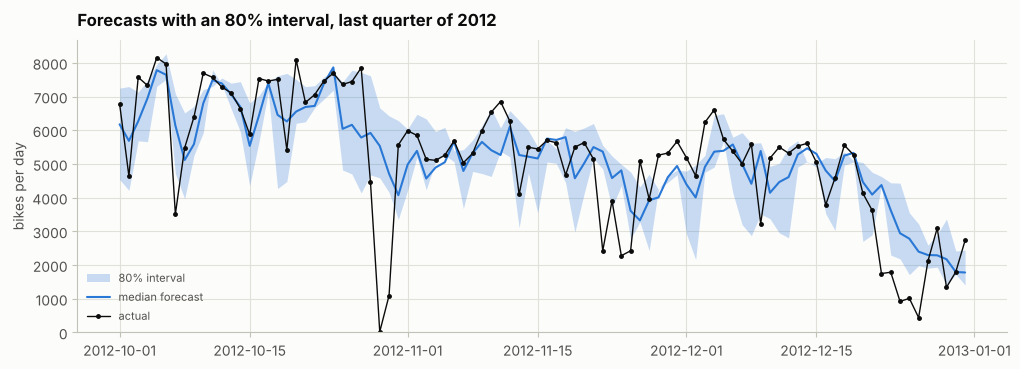

share of days inside the 80% interval: 52%
median width of the interval: 1,473 bikes


In [14]:
data = honest.assign(target=daily).dropna()
train, test_part = data[:"2012-09-30"], data[test_start:]
X_train, y_train = train.drop(columns="target"), train["target"]
X_test, y_test = test_part.drop(columns="target"), test_part["target"]

quantile_models = {q: HistGradientBoostingRegressor(loss="quantile", quantile=q, max_iter=200, learning_rate=0.05, random_state=0).fit(X_train, y_train)
                   for q in [0.1, 0.5, 0.9]}
low, mid, high = (quantile_models[q].predict(X_test) for q in [0.1, 0.5, 0.9])

fig, ax = plt.subplots(figsize=(12, 3.8))
ax.fill_between(y_test.index, low, high, color=PALETTE[0], alpha=0.25, label="80% interval")
ax.plot(y_test.index, mid, color=PALETTE[0], linewidth=1.5, label="median forecast")
ax.plot(y_test.index, y_test, color=INK, linewidth=1, marker="o", markersize=2.5, label="actual")
ax.set_ylabel("bikes per day")
ax.set_ylim(0, None)
ax.legend(loc="lower left", fontsize=8)
ax.set_title("Forecasts with an 80% interval, last quarter of 2012")
plt.show()
inside = (y_test >= low) & (y_test <= high)
print(f"share of days inside the 80% interval: {inside.mean():.0%}")
print(f"median width of the interval: {np.median(high - low):,.0f} bikes")

Always **check the coverage** on test data: an "80% interval" should contain the actual value on about 80% of days. Here it contains far fewer. The intervals are **too narrow**: the model is overconfident. The quantile models learnt how far off they tend to be **on their training data**, where they fit well, and the test quarter, with its record levels, a hurricane (the dip to almost zero at the end of October) and the winter drop, is harder than that.

### Calibrating the interval

A simple and widely used fix is **conformal prediction** (developed by Vladimir Vovk and colleagues). Set aside a recent **calibration** period that the models don't train on, measure how far the actual values fall outside the intervals there, and widen the intervals by enough to cover 80% of those calibration days:

In [15]:
fit_part, calibration = data[:"2012-06-30"], data["2012-07-01":"2012-09-30"]
low_model, high_model = (HistGradientBoostingRegressor(loss="quantile", quantile=q, max_iter=200, learning_rate=0.05, random_state=0)
                         .fit(fit_part.drop(columns="target"), fit_part["target"]) for q in [0.1, 0.9])

X_cal, y_cal = calibration.drop(columns="target"), calibration["target"]
outside = np.maximum(low_model.predict(X_cal) - y_cal, y_cal - high_model.predict(X_cal))   # negative when inside
n_cal = len(y_cal)
widen = np.quantile(outside, min(1.0, np.ceil(0.8 * (n_cal + 1)) / n_cal), method="higher")

low_c = low_model.predict(X_test) - widen
high_c = high_model.predict(X_test) + widen
inside_c = (y_test >= low_c) & (y_test <= high_c)
print(f"widen each side by {widen:,.0f} bikes")
print(f"coverage on the test quarter: {inside_c.mean():.0%}   (before calibration: {inside.mean():.0%})")
print(f"median width: {np.median(high_c - low_c):,.0f} bikes")

widen each side by 339 bikes
coverage on the test quarter: 75%   (before calibration: 52%)
median width: 2,408 bikes


The calibrated intervals are wider, and their coverage is much closer to the promised 80%. Conformal prediction guarantees the coverage when the future behaves like the calibration period; when it doesn't (a hurricane, a sudden change), no method can promise it. That's why the calibration period should be recent, and why coverage should be monitored as new data comes in.

Other approaches: use the spread of past forecast errors directly, or the classical statistical models, which give intervals from their equations.

# Part 2: Recommendations

## 11. The recommendation problem

A recommender system predicts which items a user will like. The data is a table with one row per **user** and one column per **item**, holding what each user thought of each item. Two kinds of data:

- **Explicit feedback**: ratings, such as 1 to 5 stars. Clear, but most people rarely rate.
- **Implicit feedback**: what people did: bought, clicked, watched, listened to. Plentiful, but ambiguous: not buying something doesn't mean disliking it, perhaps the person never saw it. The mini project uses this kind.

Either way the table is mostly empty. A typical user has rated or bought a tiny fraction of the items. The task is to fill in the blanks well enough to rank the items each user hasn't seen.

Real rating datasets, such as the well-known MovieLens collection, come with licences that don't allow them to be copied into a repository like this one. So for this part we'll **make** a ratings dataset, from a model of how people's tastes work. That has a big advantage for learning: we know the true structure, so we can check whether the methods find it.

Each of 600 users has a taste for three genres (some love action, some hate comedy); each of 300 films is a mix of the genres and has its own quality; some users rate more generously than others. Each user rates between 15 and 60 films, with popular films more likely to be rated, and each rating is a whole number from 1 to 5 with some noise.

In [16]:
rng = np.random.default_rng(0)
n_users, n_items, n_genres = 600, 300, 3
genre_mix = rng.dirichlet([0.3] * n_genres, size=n_items)     # each film's mix of genres
tastes = rng.normal(0, 1, size=(n_users, n_genres))           # each user's liking for each genre
item_quality = rng.normal(0, 0.5, n_items)
user_generosity = rng.normal(0, 0.4, n_users)
true_rating = 3.4 + user_generosity[:, None] + item_quality[None, :] + 0.9 * tastes @ genre_mix.T

popularity = np.exp(1.5 * item_quality + rng.normal(0, 0.8, n_items))
rows = []
for user in range(n_users):
    seen = rng.choice(n_items, size=rng.integers(15, 60), replace=False, p=popularity / popularity.sum())
    for item in seen:
        rows.append((user, item, int(np.clip(np.round(true_rating[user, item] + rng.normal(0, 0.6)), 1, 5))))
ratings = pd.DataFrame(rows, columns=["user", "item", "rating"])

print(f"{len(ratings):,} ratings from {n_users} users on {n_items} films")
print(f"share of the table filled in: {len(ratings) / (n_users * n_items):.1%}")
print("ratings:", ratings["rating"].value_counts().sort_index().to_dict())
ratings.head()

22,526 ratings from 600 users on 300 films
share of the table filled in: 12.5%
ratings: {1: 563, 2: 2542, 3: 6143, 4: 7450, 5: 5828}


,user,item,rating
0,0,209,5
1,0,218,4
2,0,109,4
3,0,233,4
4,0,231,3


About an eighth of the table is filled in, which is denser than most real systems (often well under 1%), but sparse enough to make the problem real.

For evaluation, hold out 20% of the ratings at random. (A real system would hold out the most **recent** ratings, as the mini project does; with made-up data there's no time order.)

In [17]:
from sklearn.model_selection import train_test_split

train_r, test_r = train_test_split(ratings, test_size=0.2, random_state=0)
global_mean = train_r["rating"].mean()


def rmse(predicted):
    return float(np.sqrt(np.mean((test_r["rating"].to_numpy() - predicted) ** 2)))


best_possible = rmse(true_rating[test_r["user"], test_r["item"]])
print(f"RMSE if we knew each user's true taste exactly: {best_possible:.3f}   (the noise in the ratings)")

RMSE if we knew each user's true taste exactly: 0.656   (the noise in the ratings)


Even a perfect model can't do better than about 0.66, because the ratings themselves are noisy (and rounded to whole stars). That's the floor every method below is aiming for.

## 12. Baselines: averages and biases

The simplest predictions:

- the **global mean** for everyone
- each film's **average** rating
- **biases**: the global mean, plus how much better or worse than average this film is rated, plus how much more or less generous this user is

Averages of a few ratings are noisy: a film rated 5 by its only two viewers isn't necessarily the best film. Adding a few "imaginary average ratings" before dividing **shrinks** small groups towards the global mean, the same idea as regularisation in Module 12:

$$b_i = \frac{\sum (r - \mu)}{n_i + \lambda}$$

In [18]:
shrink = 5
item_stats = train_r.groupby("item")["rating"].agg(["sum", "count"])
item_bias = ((item_stats["sum"] - item_stats["count"] * global_mean) / (item_stats["count"] + shrink)).reindex(range(n_items), fill_value=0.0)
after_items = train_r["rating"] - global_mean - item_bias[train_r["item"]].to_numpy()
user_stats = after_items.groupby(train_r["user"]).agg(["sum", "count"])
user_bias = (user_stats["sum"] / (user_stats["count"] + shrink)).reindex(range(n_users), fill_value=0.0)


def baseline(users, items):
    return global_mean + item_bias[items].to_numpy() + user_bias[users].to_numpy()


results = {
    "global mean": rmse(np.full(len(test_r), global_mean)),
    "film average (shrunk)": rmse(global_mean + item_bias[test_r["item"]].to_numpy()),
    "film and user biases": rmse(baseline(test_r["user"], test_r["item"])),
}
pd.Series(results, name="test RMSE").round(3)

global mean              1.062
film average (shrunk)    0.983
film and user biases     0.814
Name: test RMSE, dtype: float64

Biases alone take a big step from the global mean. They capture "this film is good" and "this person rates generously", but not **personal taste**: they predict the same ordering of films for everyone. Recommending is about the part biases miss.

## 13. Collaborative filtering with similarities

**Collaborative filtering** uses the ratings of many users to help each one: people who agreed in the past will probably agree in the future. The classic version is **item-based**:

1. Measure how similar every pair of films is, by comparing the ratings they received from the same users.
2. To predict a user's rating for a film, look at the films they've already rated that are most similar to it, and take a weighted average of their ratings.

Item-based filtering was popularised by Amazon, which described its "customers who bought this also bought" system in a 2003 paper by Greg Linden, Brent Smith and Jeremy York.

The **cosine similarity** of two films compares their columns of ratings. We first subtract the biases, so that "everyone rates this film highly" doesn't count as similarity; what's left is whether the **same people** liked both:

In [19]:
residual = (train_r["rating"] - baseline(train_r["user"], train_r["item"])).to_numpy()
R = np.zeros((n_users, n_items))
R[train_r["user"], train_r["item"]] = residual
observed = np.zeros((n_users, n_items), dtype=bool)
observed[train_r["user"], train_r["item"]] = True

norms = np.sqrt((R ** 2).sum(axis=0))
norms[norms == 0] = 1
similarity = (R.T @ R) / np.outer(norms, norms)              # cosine similarity between films
np.fill_diagonal(similarity, 0)


def item_knn_predict(user, item, k=20):
    rated = np.flatnonzero(observed[user])
    neighbours = rated[np.argsort(-similarity[item, rated])[:k]]
    weights = similarity[item, neighbours]
    weights = np.clip(weights, 0, None)                       # use only positively similar films
    if weights.sum() == 0:
        return baseline([user], [item])[0]
    return baseline([user], [item])[0] + weights @ R[user, neighbours] / weights.sum()


knn_predictions = np.array([item_knn_predict(u, i) for u, i in zip(test_r["user"], test_r["item"])])
results["item-based, 20 neighbours"] = rmse(knn_predictions)
pd.Series(results, name="test RMSE").round(3)

global mean                  1.062
film average (shrunk)        0.983
film and user biases         0.814
item-based, 20 neighbours    0.719
Name: test RMSE, dtype: float64

The item-based method improves on the biases: it brings in personal taste. Do the similarities make sense? Since we made the data, we can check: films with similar genre mixes should be similar.

In [20]:
true_similarity = np.corrcoef(genre_mix)
upper = np.triu_indices(n_items, k=1)
enough = (observed.sum(axis=0)[:, None] >= 20) & (observed.sum(axis=0)[None, :] >= 20)
print(f"correlation between learnt and true film similarity (films with 20+ ratings): "
      f"{np.corrcoef(similarity[upper][enough[upper]], true_similarity[upper][enough[upper]])[0, 1]:.2f}")

correlation between learnt and true film similarity (films with 20+ ratings): 0.46


A clear positive relationship: from ratings alone, the method has partly recovered which films share genres. It's far from perfect, because each pair of films has only a handful of users in common.

## 14. Matrix factorisation

**Matrix factorisation** became famous through the Netflix Prize (2006 to 2009), a public competition to improve Netflix's rating predictions by 10%. The winning teams relied heavily on it.

The idea: describe every user and every film with a short list of `f` numbers, called **factors**, so that the predicted rating is

$$\hat{r}_{ui} = \mu + b_u + b_i + \mathbf{p}_u \cdot \mathbf{q}_i$$

The factors are learnt from the ratings, and no one tells the model what they mean. With enough data they come to represent things like genres: one number might measure how much a film is a comedy and how much a user likes comedies. It's the same idea as PCA (Module 15): a big table approximated by the product of two thin ones, except that most of the table is missing, so we fit only the entries we know.

**Alternating least squares** (ALS) fits it neatly. If the film factors were fixed, finding each user's factors would be an ordinary ridge regression (Module 12) on the films that user rated, and the other way round. So alternate: solve for all users, then all films, and repeat.

In [21]:
def als(train, f, reg, n_iter=15, seed=0):
    rng_als = np.random.default_rng(seed)
    P = rng_als.normal(0, 0.1, size=(n_users, f))
    Q = rng_als.normal(0, 0.1, size=(n_items, f))
    users, items = train["user"].to_numpy(), train["item"].to_numpy()
    target = (train["rating"] - baseline(train["user"], train["item"])).to_numpy()   # fit what the biases miss
    by_user, by_item = train.groupby("user").indices, train.groupby("item").indices
    for _ in range(n_iter):
        for u, rows_u in by_user.items():           # ridge regression for each user, film factors fixed
            Qu = Q[items[rows_u]]
            P[u] = np.linalg.solve(Qu.T @ Qu + reg * np.eye(f), Qu.T @ target[rows_u])
        for i, rows_i in by_item.items():           # ridge regression for each film, user factors fixed
            Pi = P[users[rows_i]]
            Q[i] = np.linalg.solve(Pi.T @ Pi + reg * np.eye(f), Pi.T @ target[rows_i])
    return P, Q


grid = {}
for f in [1, 2, 3, 5, 10]:
    for reg in [1, 5, 15]:
        P, Q = als(train_r, f, reg)
        grid[(f, reg)] = rmse(baseline(test_r["user"], test_r["item"]) + np.sum(P[test_r["user"]] * Q[test_r["item"]], axis=1))
table = pd.Series(grid).unstack().round(3)
table.index.name, table.columns.name = "factors", "regularisation"
table

regularisation,1,5,15
factors,,,
1,0.751,0.753,0.782
2,0.689,0.699,0.765
3,0.715,0.705,0.765
5,0.754,0.715,0.765
10,0.844,0.725,0.765


(Choosing settings by looking at the test set is a shortcut for the lesson; in practice you'd use a validation set or cross-validation.)

The pattern is the one from Module 12, in a new setting:

- **Too few factors** (1) can't describe three genres: underfitting.
- **Two or three factors** with mild regularisation get close to the best possible RMSE: the data really has three genres, though one factor fewer loses little.
- **Many factors** with weak regularisation overfit: 10 factors with a penalty of 1 is worse than the biases alone. Stronger regularisation rescues them.

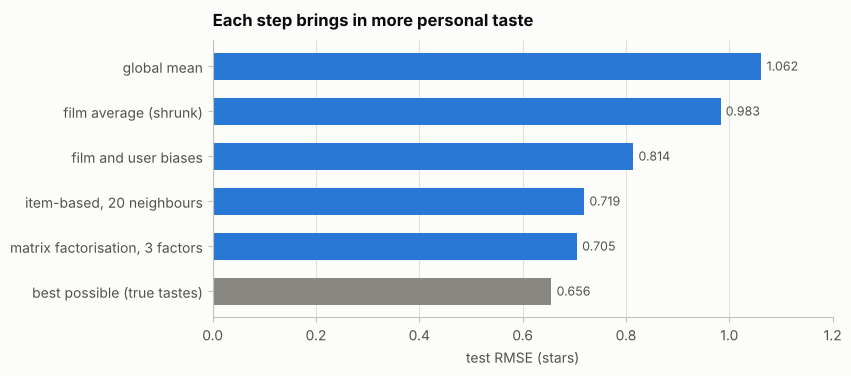

correlation between learnt film factors (rows) and true genre shares (columns):
          genre A  genre B  genre C
factor 1     0.12     0.37    -0.49
factor 2     0.80    -0.09    -0.69
factor 3    -0.32     0.86    -0.57


In [22]:
P3, Q3 = als(train_r, 3, 5)
results["matrix factorisation, 3 factors"] = rmse(baseline(test_r["user"], test_r["item"]) + np.sum(P3[test_r["user"]] * Q3[test_r["item"]], axis=1))
results["best possible (true tastes)"] = best_possible

fig, ax = plt.subplots(figsize=(8, 3.6))
names = list(results)
ax.barh(names[::-1], [results[n] for n in names[::-1]], color=[MUTED if "best" in n else PALETTE[0] for n in names[::-1]], height=0.6)
for i, n in enumerate(names[::-1]):
    ax.text(results[n] + 0.01, i, f"{results[n]:.3f}", va="center", color=INK_2, fontsize=9)
ax.set_xlim(0, 1.2)
ax.set_xlabel("test RMSE (stars)")
ax.grid(axis="y", visible=False)
ax.set_title("Each step brings in more personal taste")
plt.show()

learnt_vs_true = np.corrcoef(np.c_[Q3, genre_mix].T)[:3, 3:]
print("correlation between learnt film factors (rows) and true genre shares (columns):")
print(pd.DataFrame(learnt_vs_true, index=["factor 1", "factor 2", "factor 3"], columns=["genre A", "genre B", "genre C"]).round(2).to_string())

Matrix factorisation gets the closest to the noise floor. And two of the learnt factors relate strongly to the hidden genres (correlations around 0.8), even though the model was never told that genres exist. The factors don't line up one-to-one with genres, and they don't need to: any rotation of the factors fits the data equally well, and since each film's three genre shares add up to 1, two numbers are enough to describe a film's genre mix.

## 15. Evaluating recommenders

RMSE on held-out ratings is a convenient measure, but it doesn't match how recommendations are used. A user sees a short list, so what matters is whether the **top few** items are good. Ranking metrics measure that:

- **Precision at k**: of the `k` items recommended, what fraction did the user actually like (or buy)?
- **Recall at k**: of the items the user liked, what fraction made it into the top `k`?
- **Hit rate at k**: the share of users with at least one good item in their top `k`.

Let's recommend 10 films to each user from the films they haven't rated in training, and count a film in the test set rated 4 or 5 as a "hit":

In [23]:
liked_in_test = test_r[test_r["rating"] >= 4].groupby("user")["item"].apply(set)


def evaluate_top_k(scores, k=10):
    """scores: users × films array; already-rated films are excluded."""
    scores = np.where(observed, -np.inf, scores)
    precision, hits, true_quality = [], [], []
    for user, liked in liked_in_test.items():
        top = np.argsort(-scores[user])[:k]
        found = len(liked & set(top))
        precision.append(found / k)
        hits.append(found > 0)
        true_quality.append(true_rating[user, top].mean())     # only possible because we made the data
    return {"precision@10": np.mean(precision), "hit rate@10": np.mean(hits), "true rating of the 10 films": np.mean(true_quality)}


popularity_scores = np.tile(observed.sum(axis=0).astype(float), (n_users, 1))
bias_scores = global_mean + item_bias.to_numpy()[None, :] + user_bias.to_numpy()[:, None]
mf_scores = bias_scores + P3 @ Q3.T

pd.DataFrame({"most popular films": evaluate_top_k(popularity_scores),
              "highest film bias": evaluate_top_k(bias_scores),
              "matrix factorisation": evaluate_top_k(mf_scores)}).T.round(3)

,precision@10,hit rate@10,true rating of the 10 films
most popular films,0.133,0.730,4.270
highest film bias,0.074,0.516,4.540
matrix factorisation,0.092,0.606,4.816


This result is worth reading slowly.

By the usual offline measures, precision and hit rate, **recommending the most popular films wins clearly**. But the last column, which we can only compute because we made the data, tells the opposite story: the films that matrix factorisation recommends are the ones these users would actually rate highest, by a wide margin, and the popular films are rated lowest of the three.

How can both be true? A film can only count as a hit if the user **rated it** in the test set, and which films people rate is driven by popularity (we built the data that way, and real data works the same way). So the offline test rewards recommending films people were going to watch anyway, and can't give credit for a great film the user simply hadn't come across. Statisticians call this data **missing not at random**: which entries are missing depends on what they would have been.

This trap is one of the best-known problems in evaluating recommenders. Offline metrics computed on logged behaviour favour popular items, and a system tuned only on them drifts towards recommending what everyone already sees. Recommending popular items is still a strong, cheap baseline, and any method should be compared with it, but the offline numbers aren't the whole truth. That's why real systems also use **online experiments**.

Beyond accuracy, real systems care about:

- **Coverage and diversity**: does the system recommend many different items, or the same blockbusters to everyone? Popularity-based systems make popular items more popular, a feedback loop called **popularity bias**.
- **Cold start**: a new user has no history and a new item has no ratings, so collaborative filtering has nothing to work with. Common fixes: ask a few questions when someone joins, recommend popular items at first, or use **content** (genres, descriptions, product categories) alongside the ratings.
- **Evaluation over time**: train on the past, test on what users did next. Random splits leak future tastes into training, just as with time series.
- **Online testing**: the final judge is an experiment with real users (an A/B test), measuring whether people actually watch, buy or come back more.

## Summary

**Time series**

- Order matters, observations depend on each other, and only the past can be used. Check for gaps and use a regular index (`asfreq`).
- Series combine **trend**, **seasonality** (additive or multiplicative) and **noise**. **Autocorrelation** is why forecasting works.
- Always compute **baselines**: naive, seasonal naive, moving averages. Use MAE and RMSE; treat MAPE with care; MASE compares with the naive forecast.
- **Exponential smoothing** weights the past with fading weights; Holt and Holt-Winters add trend and seasonality; ARIMA is the other classic family.
- Validate with **time-ordered** splits (`TimeSeriesSplit`); random K-fold is far too optimistic.
- Forecasting as supervised learning: **lags, rolling features (shift first!), calendar** and known future information, then gradient boosting. Ask of every feature: would I know this at forecast time?
- Errors **grow with the horizon**. Recursive forecasts feed predictions back in; direct forecasts train one model per horizon.
- Trees **can't extrapolate** a trend: model ratios or differences.
- Give **prediction intervals** (quantile regression) and check their coverage.

**Recommendations**

- A sparse users × items table of **explicit** ratings or **implicit** actions.
- Baselines: global mean, then **biases** for users and items, **shrunk** towards the mean.
- **Item-based collaborative filtering**: weighted averages of a user's ratings for similar items, with cosine similarity on bias-adjusted ratings.
- **Matrix factorisation**: users and items as short vectors of factors, fitted by **alternating least squares** (ridge regressions); the factors recover hidden structure like genres.
- Evaluate with **ranking metrics** (precision, recall and hit rate at k), compare with **popularity**, and watch coverage, cold start, and time-ordered evaluation.

Next, open `02_exercises.ipynb`.